In [57]:
import pandas as pd
import numpy as np
import os
from sklearn.decomposition import PCA
import wfdb
import matplotlib.pyplot as plt
import torch
import json
from torch import nn as nn
from collections import OrderedDict
from torch.utils.data import DataLoader
from scipy.interpolate import interp1d
from ECGFounder_files.net1d import Net1D

from sklearn.manifold import TSNE
# from ECGFounder_files.ptbxl_eval import PTBXL_Dataset

from tqdm import tqdm # progress bar, took a while to run model, want to see this

In [2]:
N_ROWS = 1500 # number of rows to read, 1500 first rows (1499 lines of data) for instance for simplicity

In [3]:
# ECGFounders PTBXL_Dataset class
# Defining it here rather than importing, don't need all their code execution
class PTBXL_Dataset(torch.utils.data.Dataset):
    def __init__(self, ecg_path, csv_path):

        self.data = pd.read_csv(csv_path)
        self.data = self.data.iloc[:N_ROWS].copy() # limit read to first n rows
        self.data = self.data.dropna(subset=['filename_hr']) # removed label
        self.fs = 5000
        self.ecg_path = ecg_path

    def z_score_normalization(self, signal):
        return (signal - np.mean(signal)) / (np.std(signal) + 1e-8)

    def resample_unequal(self, ts, fs_in, fs_out):
        if fs_in == 0 or len(ts) == 0:
            return ts
        t = ts.shape[1] / fs_in
        fs_in, fs_out = int(fs_in), int(fs_out)

        if fs_out == fs_in:
            return ts
        if 2 * fs_out == fs_in:
            return ts[:, ::2]

        resampled_ts = np.zeros((ts.shape[0], fs_out))
        x_old = np.linspace(0, t, num=ts.shape[1], endpoint=True)
        x_new = np.linspace(0, t, num=int(fs_out), endpoint=True)

        for i in range(ts.shape[0]):
            y_old = ts[i, :]
            f = interp1d(x_old, y_old, kind='linear')
            resampled_ts[i, :] = f(x_new)

        return resampled_ts

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        hash_file_name = row['filename_hr']
        # Likely need to adapt label logic
        # label = row['label']
        # label = json.loads(label)
        # label = torch.tensor(label, dtype=torch.float)
        
        sample_rate = 500
        data = [wfdb.rdsamp(self.ecg_path+hash_file_name)]
        data = np.array([signal for signal, meta in data])
        data = data.squeeze(0) 
        data = np.transpose(data,  (1, 0))
        data = self.z_score_normalization(data)
        signal = self.resample_unequal(data, sample_rate, self.fs)
        signal = torch.FloatTensor(signal)
        return signal # removed label

In [4]:
# Using net1d definition parameters from ptbxl_eval.py to make model - ECGFounder github
# Think Colab gpus use cuda cores, might be important for performance if code will be rerun
device = torch.device('cuda:{}'.format(0) if torch.cuda.is_available() else 'cpu')

model = Net1D(
    in_channels=12, 
    base_filters=64, #64
    ratio=1, 
    filter_list=[64, 160, 160, 400, 400, 1024, 1024], #[64, 160, 160, 400, 400, 1024, 1024]
    m_blocks_list=[2,2,2,3,3,4,4], 
    kernel_size=16, 
    stride=2, 
    groups_width=16,
    verbose=False, 
    use_bn=False,
    use_do=False,
    n_classes=150, # corresponds to the classifications in tasks.txt
    return_features=True # To get feature vector out as specified in proj tips
)

model.to(device) # Use info about cuda availability, decide where model should run
pass # Prevents excessive ipynb output

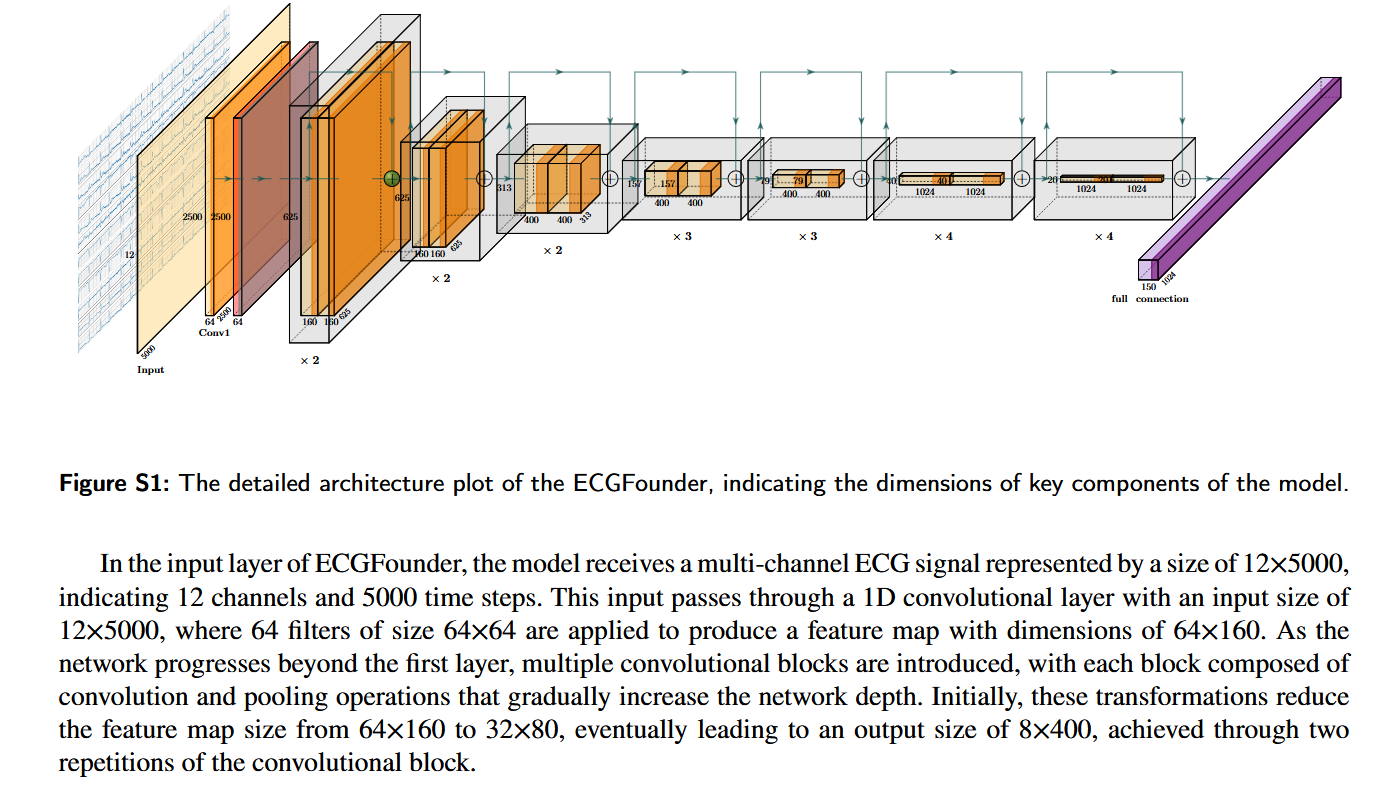

The above Figure S1 (https://arxiv.org/pdf/2410.04133) shows the various layers of the convolutional neural network that the ECGFounder model is comprised of, and how they lead to the final output of 150 possible labels.

In [5]:

# Logic from ptbxl_eval, adding weights_only=True

# Got error when unpickling weights with weights_only, did troubleshooting, this addresses it
scalar_function = np.core.multiarray.scalar
safe_objects = [
    # NumPy scalar reconstruction
    (scalar_function, "numpy.core.multiarray.scalar"),
    np.dtype,
    np.dtypes.Float32DType,
    np.dtypes.Float64DType,
    OrderedDict,
]
# Load checkpoints
with torch.serialization.safe_globals(safe_objects):
    checkpoint = torch.load("ECGFounder_files/12_lead_ECGFounder.pth",
    map_location=device,
    weights_only=True)

# Reusing and adapting code from ECGFounders public eval script mentioned in tips
state_dict = checkpoint['state_dict']
log = model.load_state_dict(state_dict, strict=False)
print(log) # Check weights load correctly

# Freeze model parameters
for name, param in model.named_parameters():
    param.requires_grad = False
model.eval() # Set model evaluation mode


pass # Avoid excessive text in output field


C:\Users\oyste\AppData\Local\Temp\ipykernel_12064\900617530.py:4: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.multiarray.
  scalar_function = np.core.multiarray.scalar


<All keys matched successfully>


In [6]:
# Get tasks
tasks = []
with open("ECGFounder_files/tasks.txt", "r") as x:
    for task in x:
        tasks.append(task.strip())

In [7]:
ecg_filepath = "../data/ptb-xl-1.0.1/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/"
csv_filepath = "../data/ptbxl_database.csv"
BATCH_SIZE = 64

In [8]:
# The expected format of the csv for the ECGFounder public eval script is as follows:
# patient_id,
# scp_codes,
# filename_lr,
# filename_hr,
# diagnostic_superclass,
# diagnostic_subclass,
# rhythm,
# form,
# diagnosis,
# label

# label seems to be one-hot encoded diagnoses with indexes corresponding to the lines of tasks.txt?
# will try to map diagnoses to these labels and recreate them then, since the dataset we're instructed to use do not have these already

In [9]:

testset = PTBXL_Dataset(ecg_path=ecg_filepath, csv_path=csv_filepath)
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0) # could otherwise be os.cpu_count() but this gives a bug right now




In [10]:


embeddings_collection = []

with torch.no_grad():
    for batch_idx, batch in enumerate(tqdm(testloader)):
        input_x = batch.to(device)
        logits, embeddings = model(input_x)
        embeddings_collection.append(embeddings)


100%|██████████| 24/24 [02:42<00:00,  6.77s/it]


In [ ]:
# print(embeddings_collection[0].shape)
# print(embeddings_collection[0].ndim)
# print(embeddings_collection[-1].shape)
# print(embeddings_collection[-1].ndim)
print([coll.shape for coll in embeddings_collection])


[torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([64, 1024]), torch.Size([28, 1024])] 



In [27]:
embeddings = torch.cat(embeddings_collection, dim=0)
print(embeddings.shape)

torch.Size([1500, 1024])


In [49]:
N_COMPONENTS = 20
pca = PCA(n_components=N_COMPONENTS)
principalComponents = pca.fit_transform(embeddings.cpu().numpy())

print(principalComponents.shape)
print(pca.explained_variance_ratio_.sum())


(1500, 20)
0.6350291


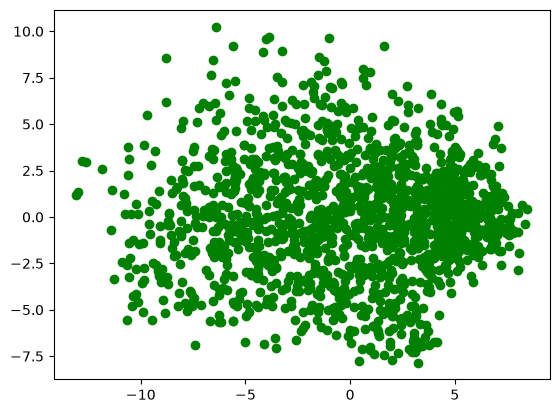

In [51]:
plt.scatter(principalComponents[:,0],principalComponents[:,1], color=['green'])


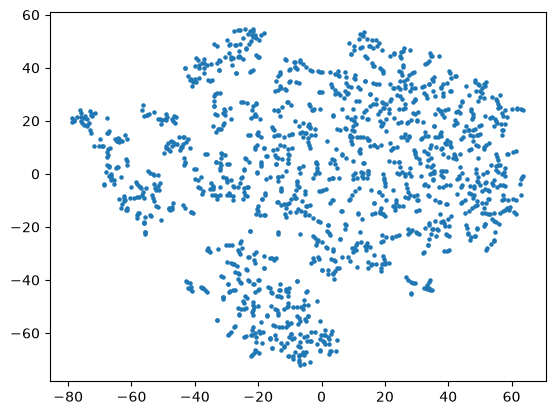

In [58]:
tsne = TSNE(
    n_components=2,
    perplexity=10,
    init='pca',
    learning_rate='auto'
)

X_tsne = tsne.fit_transform(principalComponents)

plt.scatter(X_tsne[:, 0],X_tsne[:, 1],s=5)

In [ ]:


print(type(checkpoint))
print(checkpoint.keys())



In [14]:

df = pd.read_csv("../data/ptbxl_database.csv", delimiter=",", skiprows=1, nrows=N_ROWS) # Read metadata for 1500 entries


In [15]:
df.head()

,1,15709.0,56.0,1.1,Unnamed: 4,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,Unnamed: 19,", I-V1,",Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,3,records100/00000/00001_lr,records500/00000/00001_hr
0,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
1,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
2,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
3,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr
4,6,19005.0,18.0,1,NaN,58.0,2.0,0.0,CS-12 E,1984-11-28 13:32:13,...,True,", V1",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00006_lr,records500/00000/00006_hr


In [16]:
df.shape

(1500, 28)